# Run 5a: fluxes of bright patches at known positions

Run 5's data ([run5_needlet_sky.ipynb](run5_needlet_sky.ipynb)): run 2's smooth Galaxy plus four bright patches (LMC,
SMC, Sgr dSph, bar end; 20%, 8%, 12%, 12% of the Galaxy's flux). Same seed as run 2, so **the same noise realisation**:
with the patches switched off the series equals run 2's to 3×10⁻⁵. 30 d, same WDM data settings and likelihood as runs 1–4.

Two models of the power modulation are fitted to the same WDM pixels with the same Gamma likelihood:

| | modulation model | parameters | sampler |
|---|---|---|---|
| **atoms** (runs 1–4 model) | log P_c(t) = Σ Gaussian atoms in time, level_E | 7 spectral + level_E + K atoms (RJ) | eryn, 32 walkers × 4 temperatures, 2000 + 6000 steps |
| **5a: patch fit** | P_c(t) = T_c,gal(t) + Σᵢ Fᵢ T_c,i(t) | 7 spectral + 4 fluxes Fᵢ | NUTS (numpyro), 4 chains, 1000 + 2000, whitened logit coordinates |

In 5a, $T_{c,\rm gal}$ is the smooth Galaxy (shape fixed at the truth) and $T_{c,i}$ is the modulation per unit flux of patch i
at its true position and shape ([patch_fit.py](patch_fit.py)). Fluxes are in units of the Galaxy's flux, prior U(0, 1).
Spectral priors are the uniform bounds of [config/sources.yaml](config/sources.yaml), as in runs 1–4. This is the **best
case** for a sky model: everything about the sky is known except how bright each patch is.

Compared quantity for the modulation, as in runs 3–4: the **galactic brightness recovered / injected** (amplitude ×
spectral shape × $P_c(t)$ of each posterior sample, divided by the injected one). The atom model's `amp` absorbs the
envelope level (b_A = 0), so `amp` itself is not comparable between the models.

Rerun: `python injection.py --tag run5 --injection patches` (atoms, ~25 min) and `python patch_fit.py` (5a).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import corner
import jax
import jax.numpy as jnp

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
HERE = ROOT / 'data' / 'wavelet_injection'
sys.path.insert(0, str(HERE))
import injection as I
import diagnostics as D
import patch_fit as PF
from bahamas.wavelet.model import DAY
from bahamas.wavelet.sampler import modulation_draws, _sampled

OUT = HERE / 'outputs' / 'run5'
CH = ['A', 'E']
C_TRUTH, C_AT, C_AT_L, C_PF, C_PF_L, C_MUTED = '#0b0b0b', '#2a78d6', '#86b6ef', '#eb6834', '#f5b48f', '#52514e'
C_PATCH = ['#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False,
                     'axes.spines.right': False})

data, inj = I.load_or_simulate('patches', 'run5')
like_at, post_at = I.build_posterior(data)
fit = PF.PatchFit(data)
r_at = dict(np.load(OUT / 'chains.npz', allow_pickle=True))
r_pf = dict(np.load(OUT / '5a' / 'chains.npz', allow_pickle=True))
amp_true = I.true_amp()
truth_src = {p['name']: p['injected'] for s in I.og_sources().values() for p in s}
print(f"atoms: {float(r_at['runtime_s']) / 60:.1f} min;  5a: {float(r_pf['runtime_s']) / 60:.1f} min")

2026-10-17 13:32:54,399 - BAHAMAS - INFO - Using JAX backend.


2026-10-17 13:32:54,400 - BAHAMAS - INFO - np is from: jax.numpy


atoms: 57.7 min;  5a: 56.4 min


## 1. Sampling checks

In [2]:
print(f"5a NUTS: {int(r_pf['chains'])} chains x {int(r_pf['samples'])} draws, {int(r_pf['divergences'])} divergences, "
      f"mean leapfrog steps {float(r_pf['num_steps_mean']):.0f}")
for n, rh, ne in zip(r_pf['diag_names'], r_pf['r_hat'], r_pf['n_eff']):
    print(f"   {str(n):12s} r_hat {rh:.3f}   n_eff {ne:6.0f}")
print(f"   log L: median {np.median(r_pf['log_like']):.1f}, at the truth {float(r_pf['loglike_true']):.1f}  "
      f"(expected median - truth ~ -{len(r_pf['diag_names'])}/2 + scatter)\n")
print('atoms (eryn):')
D.report(r_at, post_at, np.array([5., 15., 25.]) * DAY)
for c in CH:
    K, p = r_at[f'mod_{c}_bayes_K'], r_at[f'mod_{c}_bayes_posterior']
    print(f"   {c}: " + ' '.join(f'p(K={k})={q:.3f}' for k, q in zip(K, p) if q > 0.005))

5a NUTS: 4 chains x 2000 draws, 54 divergences, mean leapfrog steps 58
   alpha        r_hat 1.001   n_eff   2115
   amp          r_hat 1.002   n_eff   4551
   fknee        r_hat 1.002   n_eff   1923
   fr1          r_hat 1.001   n_eff   2366
   fr2          r_hat 1.001   n_eff   3916
   A            r_hat 1.002   n_eff   2185
   P            r_hat 1.001   n_eff   4934
   F_LMC        r_hat 1.014   n_eff    492
   F_SMC        r_hat 1.009   n_eff    799
   F_Sgr dSph   r_hat 1.009   n_eff   1162
   F_bar end    r_hat 1.010   n_eff   1053
   log L: median 1118878.3, at the truth 1118876.1  (expected median - truth ~ -11/2 + scatter)

atoms (eryn):


        quantity  tau_acf tau_batch      ESS  nsteps/tau
           alpha      2.0       8.4    22975       718.0
             amp      1.9       3.3    57676      1802.4
           fknee      1.6       1.9    99319      3103.7
             fr1      2.1       9.9    19358       605.0
             fr2      1.7       3.0    64471      2014.7
               A      1.7       3.8    51007      1594.0
               P      1.7       3.9    48665      1520.8
         level_E      1.9       5.5    35120      1097.5
             K_A      2.0       3.8    49977      1561.8
             K_E      2.0       3.5    55185      1724.5
           log L      2.7       5.0    38109      1190.9
        P_A(5 d)      1.9       6.3    30363       948.8
       P_A(15 d)      2.0       8.1    23572       736.6
       P_A(25 d)      2.1       8.4    22855       714.2
        P_E(5 d)      2.1       8.1    23752       742.3
       P_E(15 d)      1.9       7.2    26532       829.1
       P_E(25 d)      2.0      

## 2. Corner plots

### 2a. Patch fit (5a): spectral parameters and the four fluxes
Black lines: injected values.

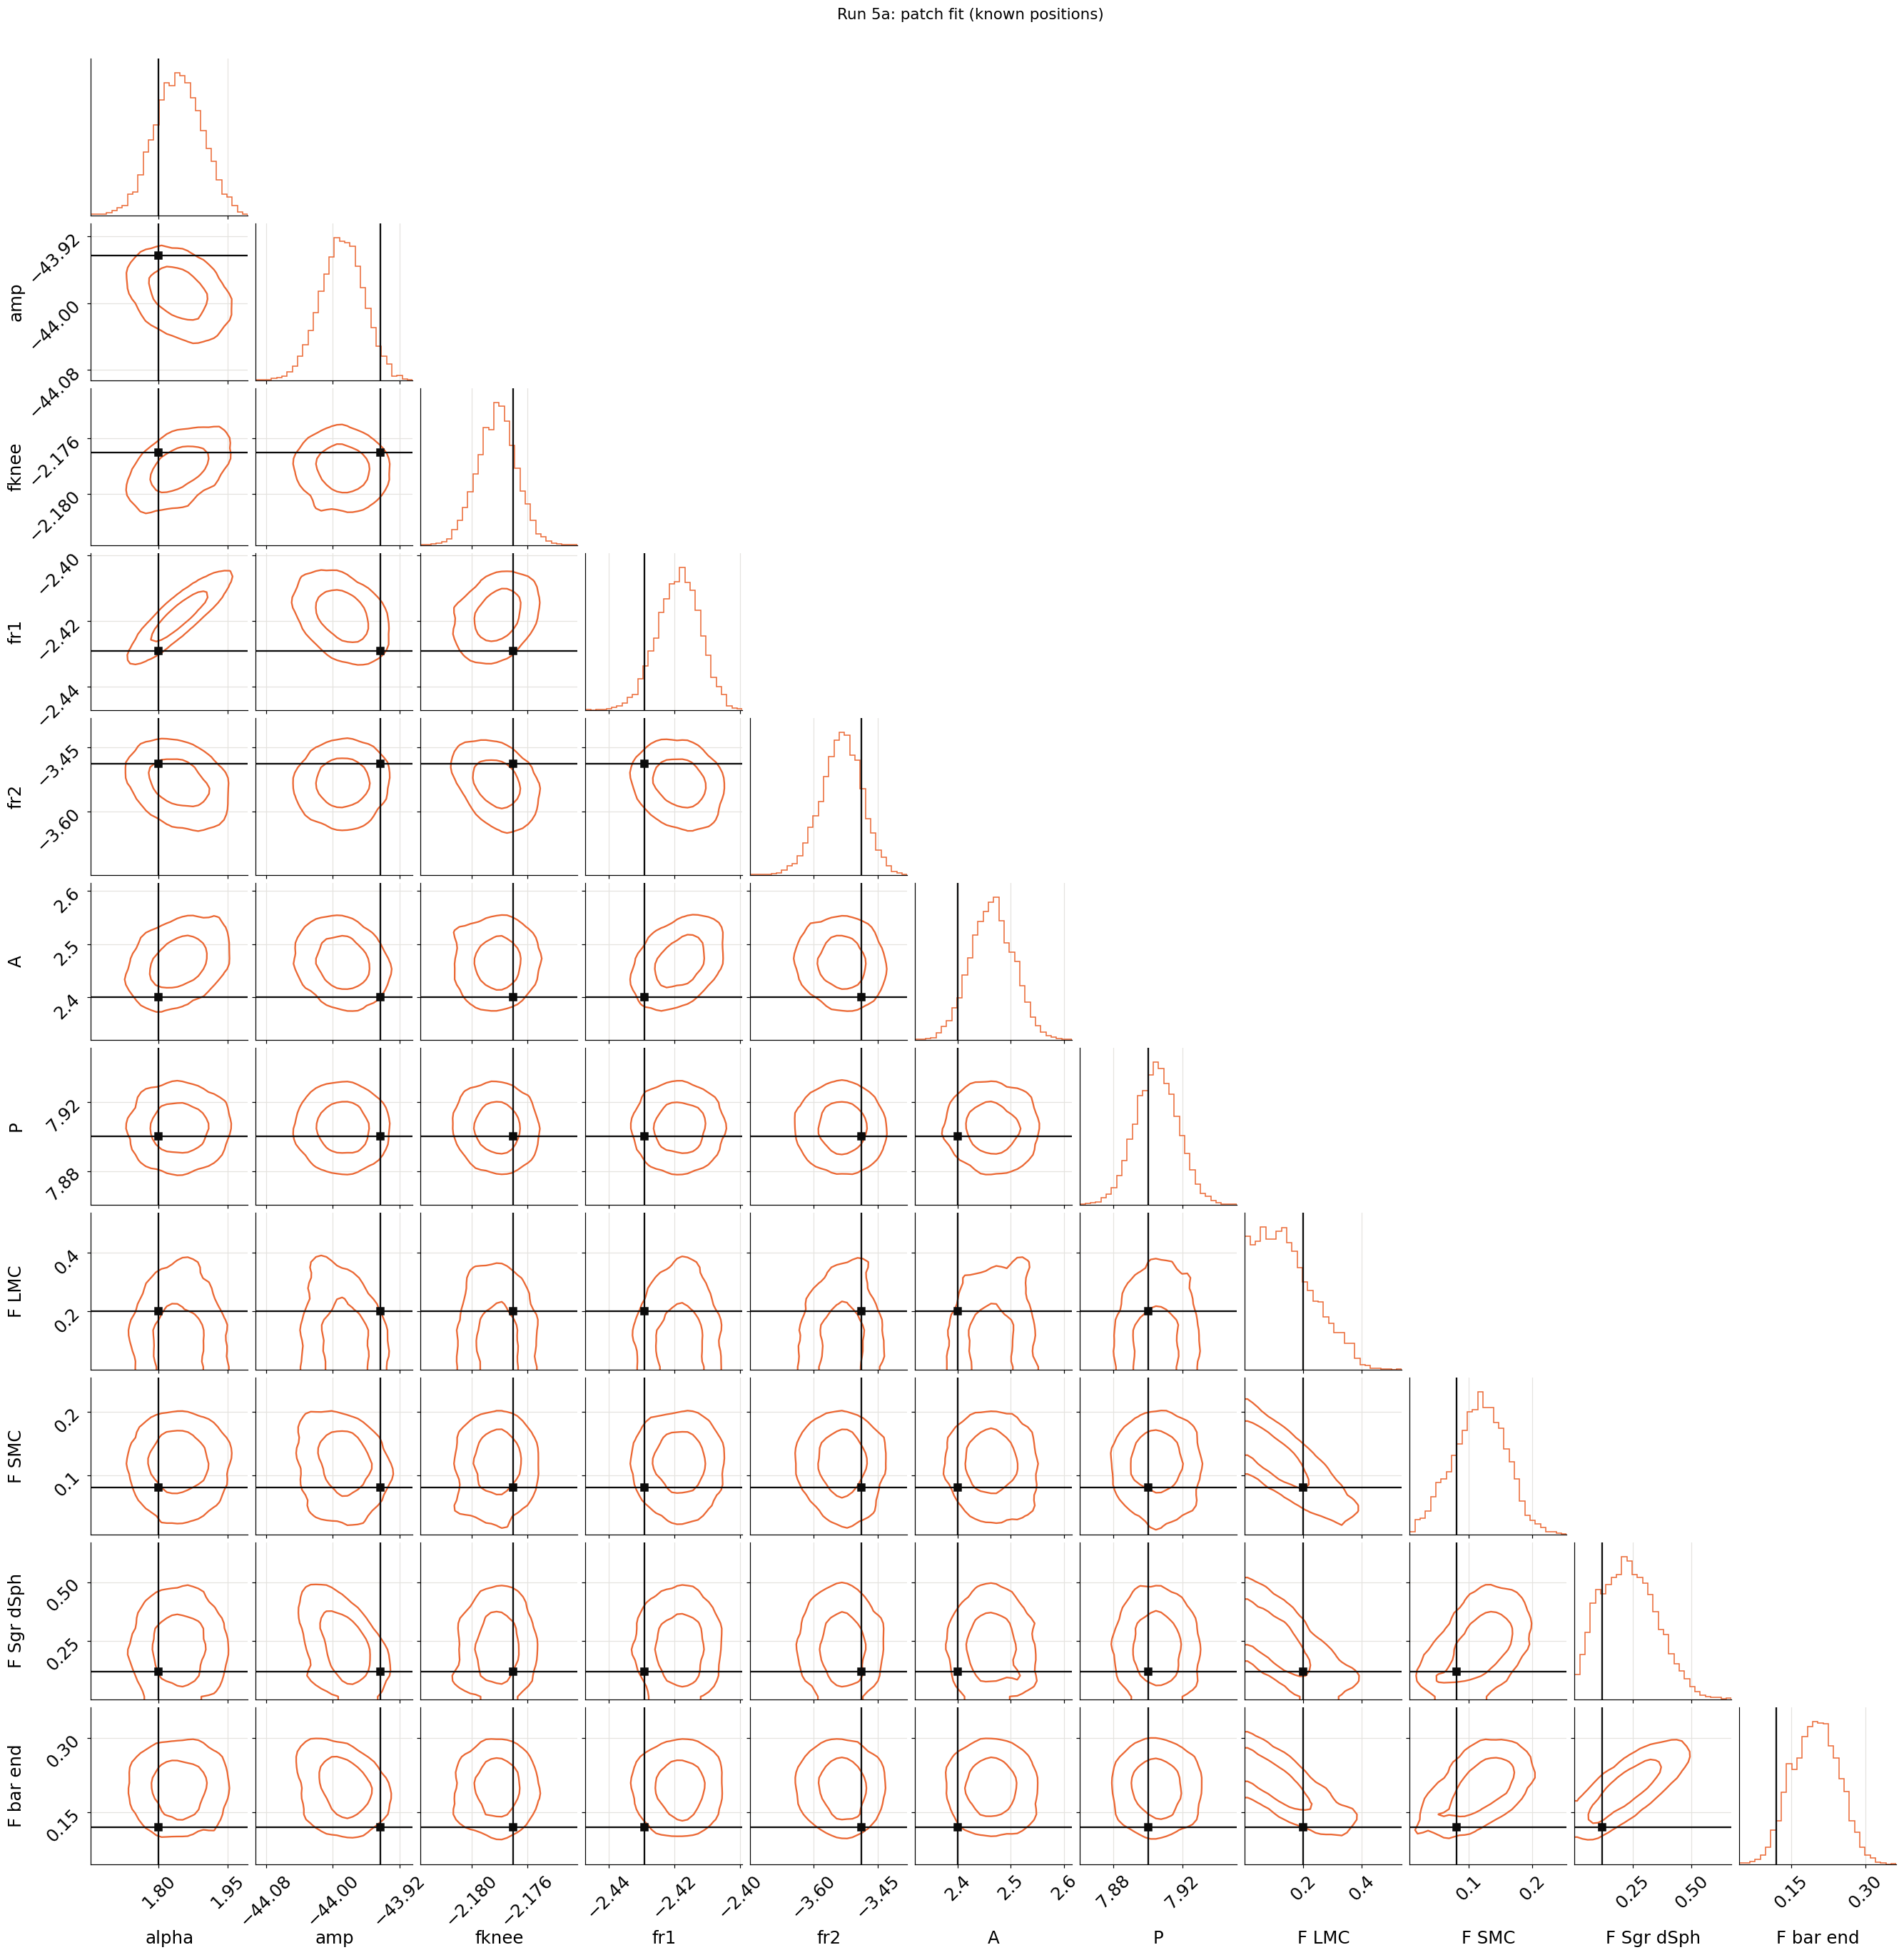

In [3]:
names_pf = [str(n) for n in r_pf['psd_names']] + [f'F {n}' for n in r_pf['patch_names']]
ch_pf = np.column_stack([r_pf['psd_chain'], r_pf['flux_chain']])
tr_pf = list(r_pf['psd_true']) + list(r_pf['flux_true'])
ckw = dict(bins=30, smooth=1.0, plot_datapoints=False, plot_density=False, levels=(0.5, 0.9), max_n_ticks=3,
           labelpad=0.12, hist_kwargs={'density': True})
fig = corner.corner(ch_pf, labels=names_pf, color=C_PF, truths=tr_pf, truth_color=C_TRUTH, **ckw)
fig.suptitle('Run 5a: patch fit (known positions)', fontsize=14, y=1.01)
fig.savefig(OUT / 'corner_5a_patchfit.png', dpi=110, bbox_inches='tight')
plt.show()

### 2b. Atoms (runs 1–4 model) on the same data
`amp` and `level_E` have no injected value in this parametrisation (the atoms carry the envelope), so no truth line.

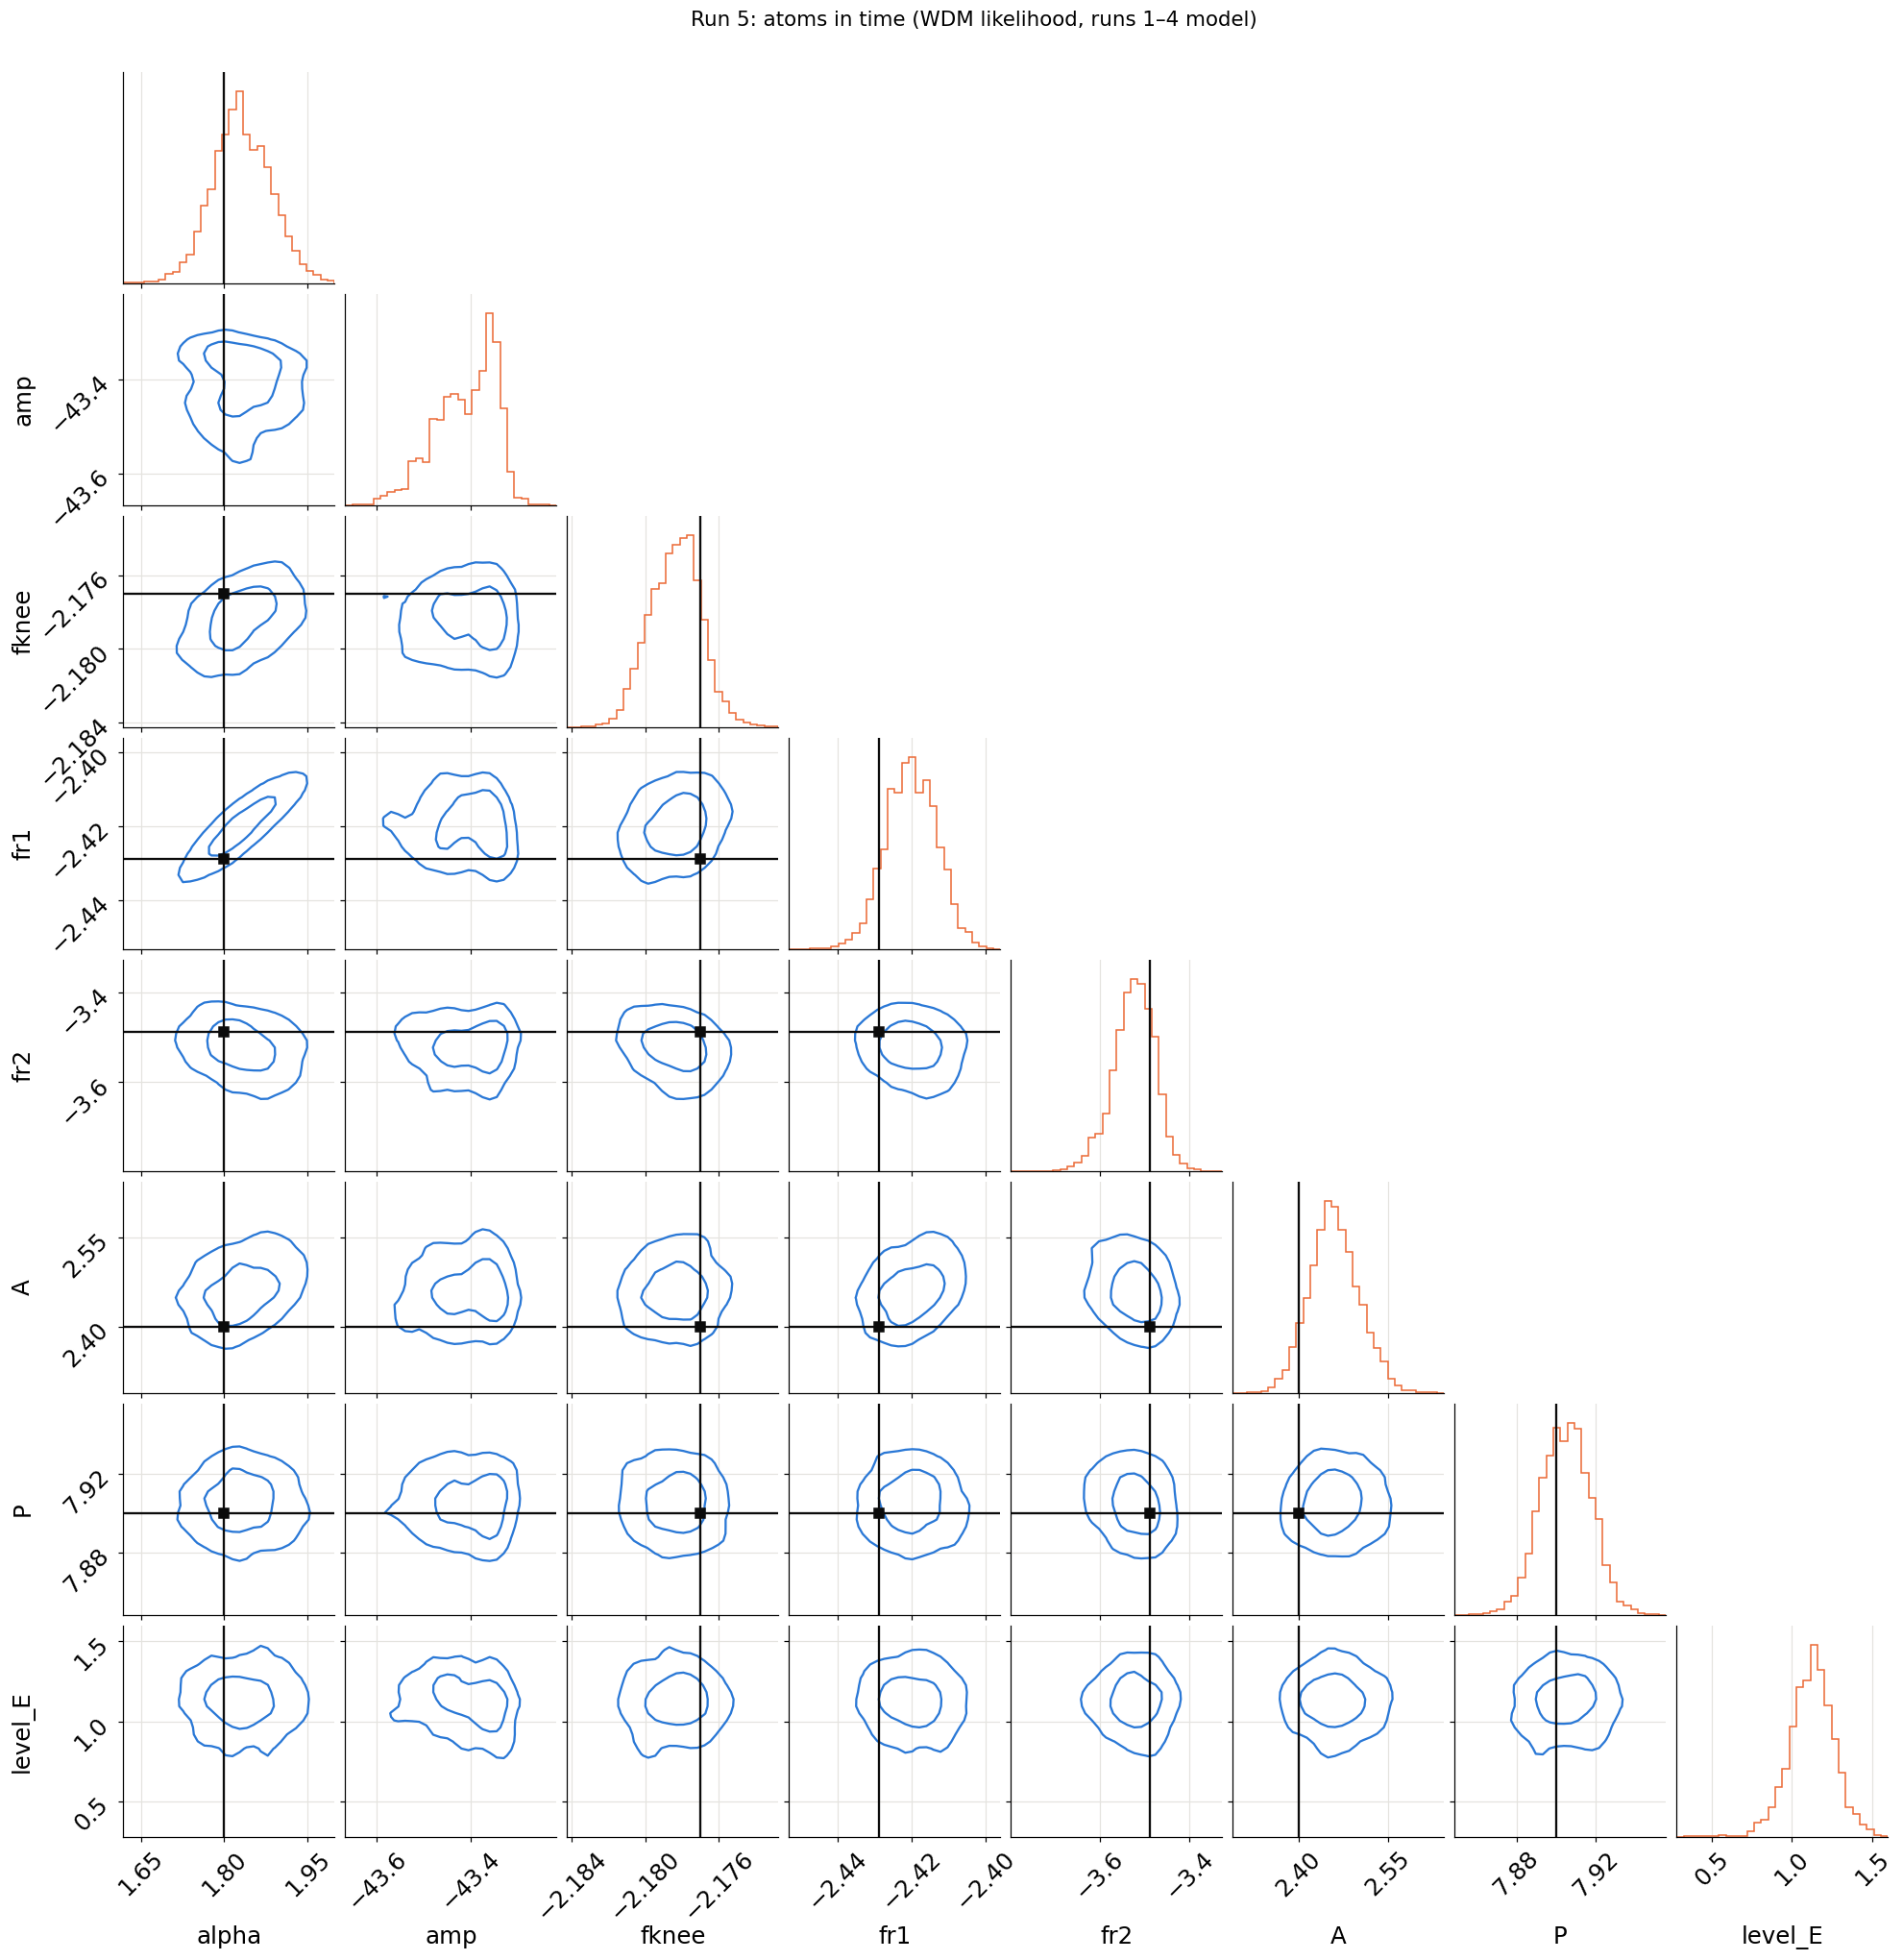

In [4]:
names_at = [str(n).split(':')[-1] for n in r_at['psd_names']]
keep_at = ['alpha', 'amp', 'fknee', 'fr1', 'fr2', 'A', 'P', 'level_E']
ch_at = np.column_stack([r_at['psd_chain'][:, names_at.index(k)] for k in keep_at])
tr_at = [truth_src.get(k) if k not in ('amp', 'level_E') else None for k in keep_at]
fig = corner.corner(ch_at, labels=keep_at, color=C_AT, truths=tr_at, truth_color=C_TRUTH, **ckw)
fig.suptitle('Run 5: atoms in time (WDM likelihood, runs 1–4 model)', fontsize=14, y=1.01)
fig.savefig(OUT / 'corner_atoms.png', dpi=110, bbox_inches='tight')
plt.show()

### 2c. Comparison on the shared quantities
The six spectral-shape and noise parameters, plus the 30-day mean galactic brightness recovered / injected in A and E
(the quantity both models measure; 1 = truth). Brightness: per posterior draw, 10^(amp − amp_true) × the
information-weighted ratio of its galactic spectrum to the true one × the 30-day mean of its $P_c(t)$ over the true one.

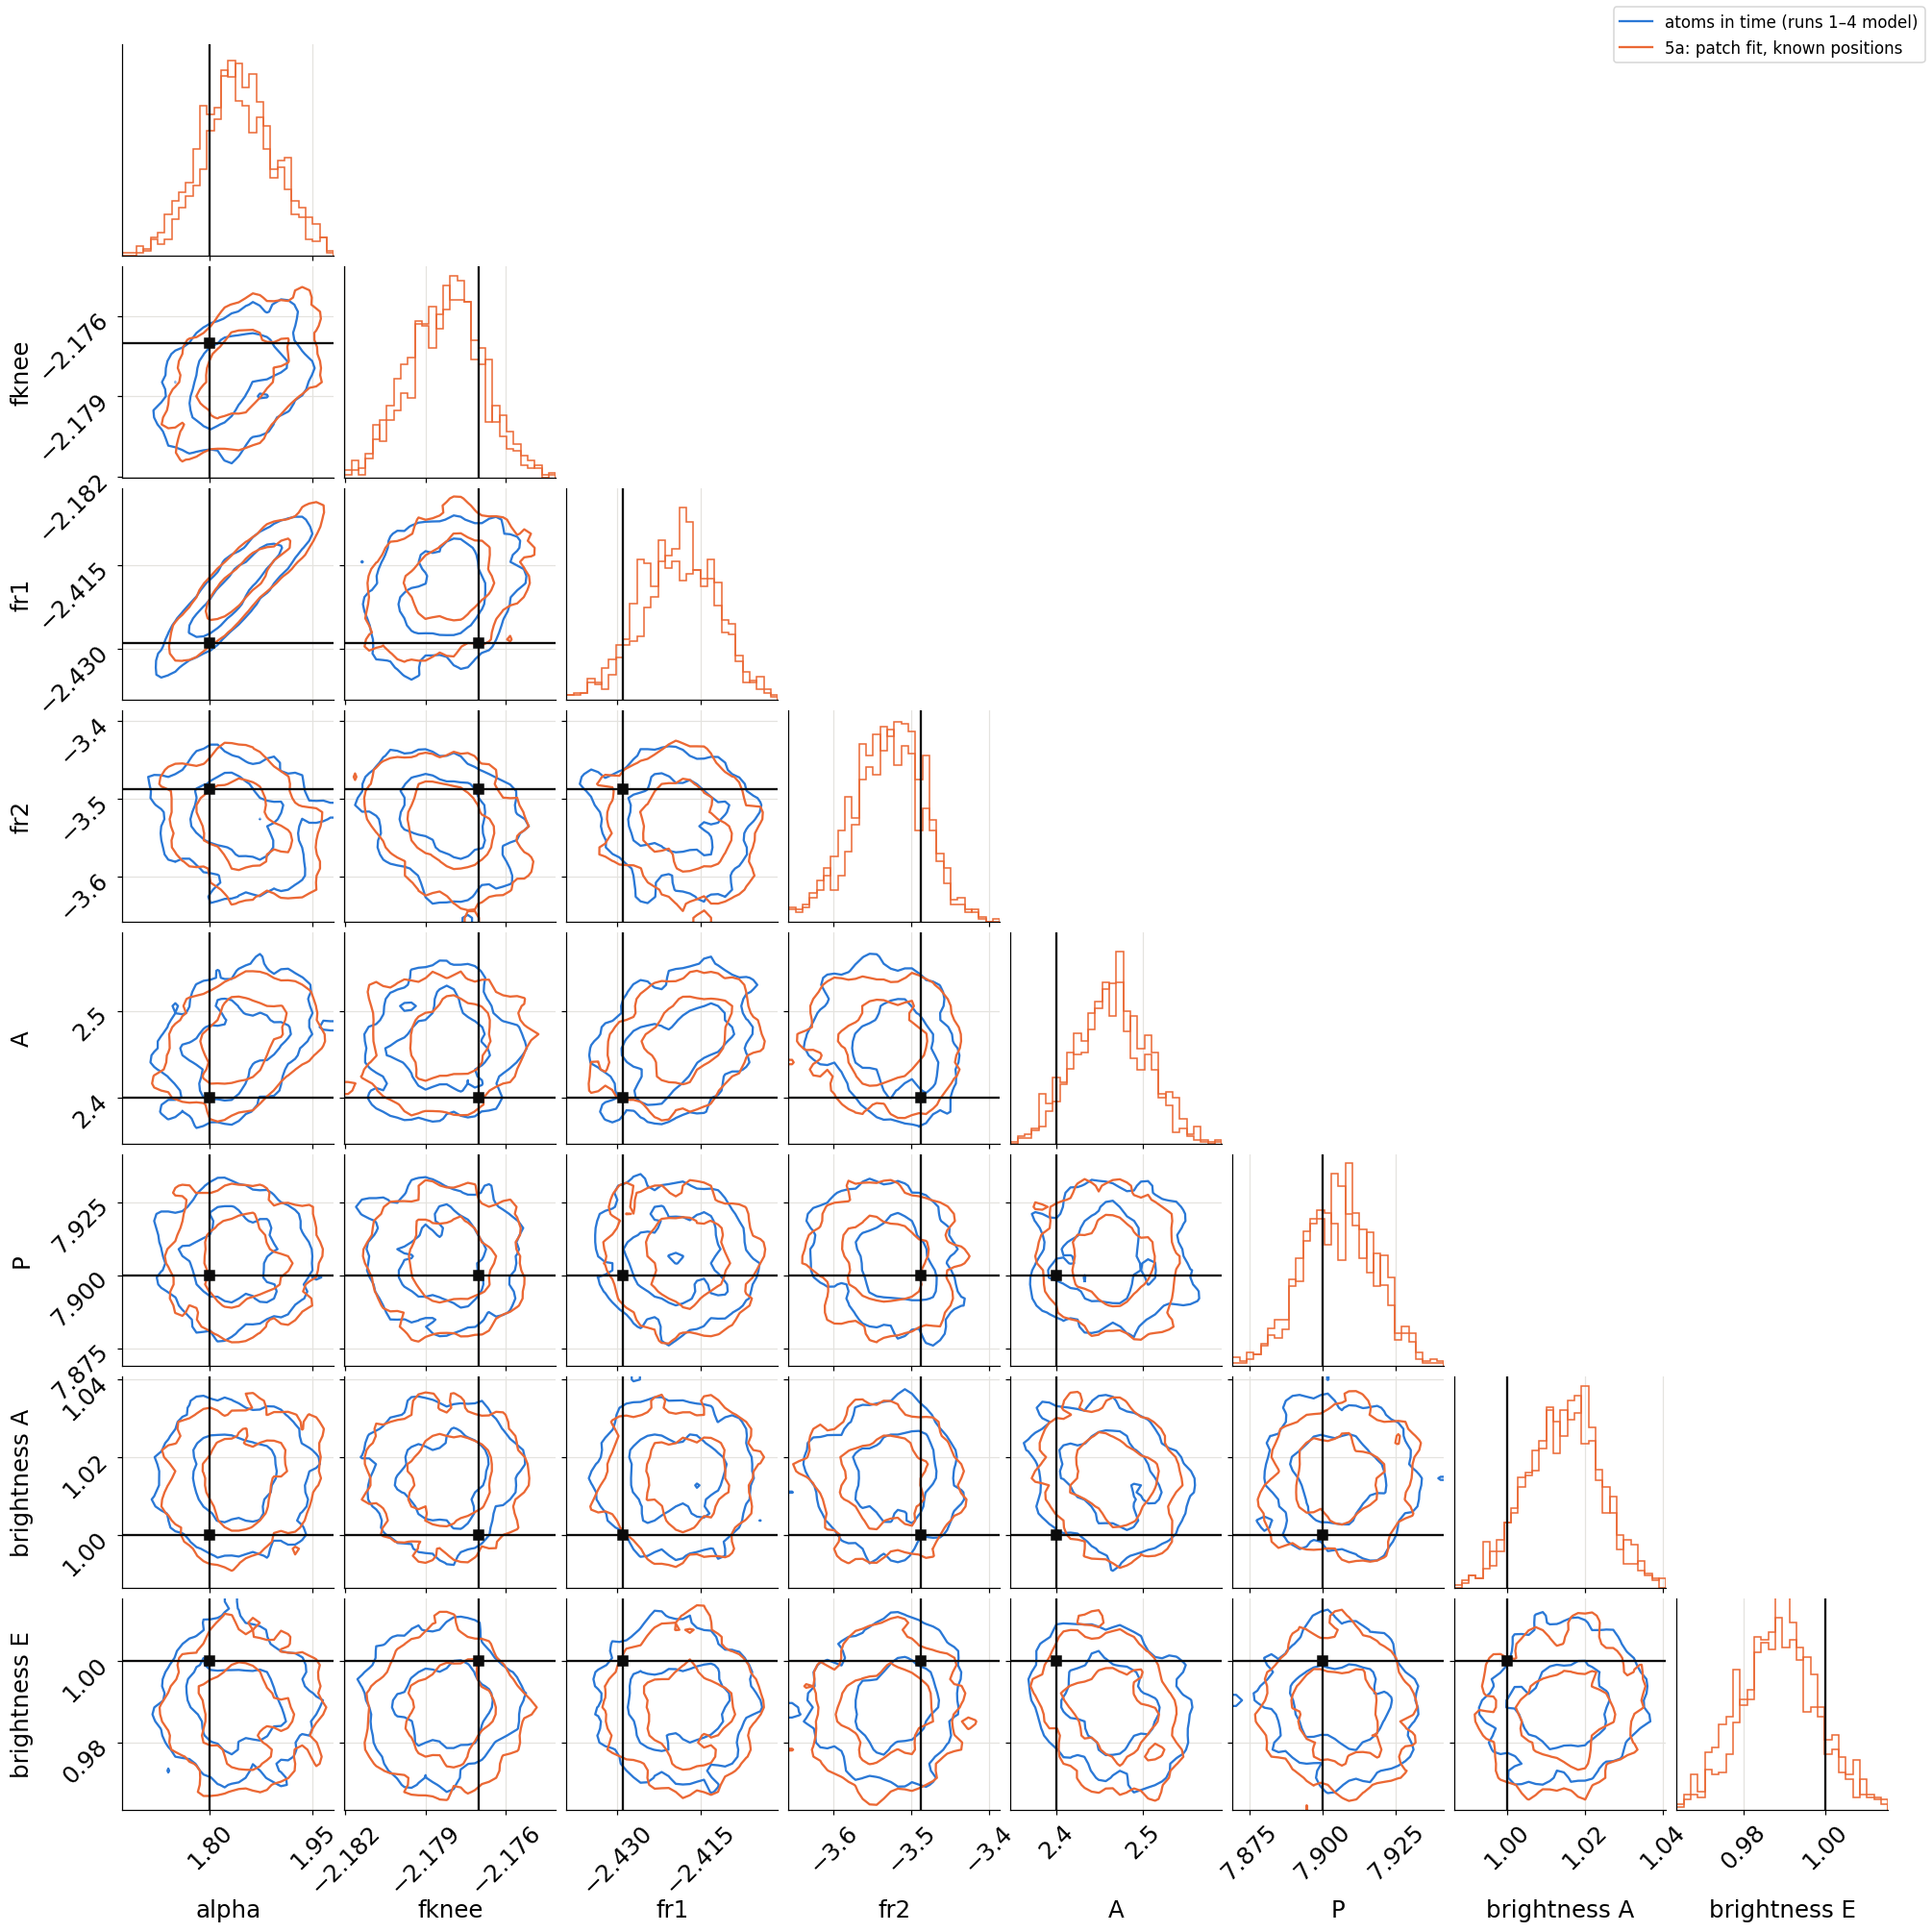

param            truth |   atoms: median, 90% width |    5a: median, 90% width | width 5a/atoms
alpha            1.800 |       1.8333       0.1753 |      1.8449      0.1767 | 1.008
fknee           -2.177 |      -2.1783       0.0045 |     -2.1781      0.0048 | 1.062
fr1             -2.429 |      -2.4198       0.0225 |     -2.4180      0.0215 | 0.956
fr2             -3.488 |      -3.5230       0.1495 |     -3.5331      0.1495 | 1.000
A                2.400 |       2.4603       0.1455 |      2.4643      0.1277 | 0.878
P                7.900 |       7.9059       0.0398 |      7.9051      0.0409 | 1.027
brightness A     1.000 |       1.0150       0.0317 |      1.0144      0.0315 | 0.992
brightness E     1.000 |       0.9899       0.0317 |      0.9878      0.0321 | 1.013


In [5]:
t_fine = np.linspace(0, data.Nt * data.Nf * data.dt, 600)
an = np.asarray(fit.like.times)
win = (t_fine >= an[0]) & (t_fine <= an[-1])                     # analysed span (edge pixels dropped)
T_fine = fit.templates(t_fine)
P_true = np.asarray(fit.P(jnp.asarray(r_pf['flux_true']), jnp.asarray(T_fine)))      # (2, nt)
P_gal_true = T_fine[..., 0]

def spectral_ratio(post, chain, names):
    # information-weighted S_gal(sample) / S_gal(truth) per channel, with amp set to the truth
    theta0 = np.array([p.value for p in _sampled(post.psd_params)], float)
    th = np.array(chain, float); th[:, names.index('amp')] = theta0[names.index('amp')]
    Sg0, Sn0, _ = post.spectra(jnp.asarray(theta0)); Sg0, Sn0 = np.asarray(Sg0), np.asarray(Sn0)
    ok = Sg0 > 1e-3 * Sg0.max()
    W = np.stack([np.where(ok, np.asarray(post.like.nu) * (Sg0 / (Sg0 + Sn0[c])) ** 2, 0.) for c in (0, 1)])
    W /= W.sum(1, keepdims=True)
    Sg = np.asarray(jax.jit(jax.vmap(lambda t: post.spectra(t)[0]))(jnp.asarray(th)))
    return np.where(ok, Sg / np.where(ok, Sg0, 1.), 0.) @ W.T          # (ndraw, 2)

rng = np.random.default_rng(0)
# 5a: amp is the true-amp parametrisation
i_pf = rng.choice(len(ch_pf), 1000, replace=False)
amp_pf = r_pf['psd_chain'][i_pf, list(r_pf['psd_names']).index('amp')]
P_pf = np.stack([np.asarray(fit.P(jnp.asarray(f), jnp.asarray(T_fine))) for f in r_pf['flux_chain'][i_pf]])
B_pf = 10 ** (amp_pf - amp_true)[:, None, None] * P_pf * spectral_ratio(fit.post, r_pf['psd_chain'][i_pf], list(r_pf['psd_names']))[:, :, None] / P_true
# atoms: modulation_draws gives 10^(amp - amp_ref) P_c(t), amp_ref = amp_eff
idx_at = np.random.default_rng(0).choice(len(r_at['psd_chain']), size=1000, replace=False)
P_at = 10 ** (inj.amp_ref - amp_true) * modulation_draws(post_at, r_at, t_fine, nsamples=1000, seed=0)
th_at = r_at['psd_chain'][idx_at]
B_at = P_at * spectral_ratio(post_at, th_at, names_at)[:, :, None] / P_true      # (ndraw, 2, nt)

shared = ['alpha', 'fknee', 'fr1', 'fr2', 'A', 'P']
mean_b = lambda B: (B[:, :, win] * P_true[None, :, win]).mean(-1) / P_true[None, :, win].mean(-1)
cmp_at = np.column_stack([th_at[:, [names_at.index(k) for k in shared]], mean_b(B_at)])
cmp_pf = np.column_stack([r_pf['psd_chain'][i_pf][:, [list(r_pf['psd_names']).index(k) for k in shared]], mean_b(B_pf)])
labels = shared + ['brightness A', 'brightness E']
truths = [truth_src[k] for k in shared] + [1.0, 1.0]
rng_ = [tuple(np.percentile(np.r_[cmp_at[:, i], cmp_pf[:, i]], [0.2, 99.8])) for i in range(len(labels))]
fig = corner.corner(cmp_at, labels=labels, color=C_AT, range=rng_, **ckw)
corner.corner(cmp_pf, fig=fig, color=C_PF, range=rng_, truths=truths, truth_color=C_TRUTH, **ckw)
fig.legend(handles=[plt.Line2D([], [], color=C_AT, label='atoms in time (runs 1–4 model)'),
                    plt.Line2D([], [], color=C_PF, label='5a: patch fit, known positions')], loc='upper right', fontsize=11)
fig.savefig(OUT / 'corner_5a_vs_atoms.png', dpi=110, bbox_inches='tight')
plt.show()

print(f"{'param':13s} {'truth':>8s} | {'atoms: median, 90% width':>26s} | {'5a: median, 90% width':>24s} | width 5a/atoms")
for i, k in enumerate(labels):
    qa, qp = np.percentile(cmp_at[:, i], [5, 50, 95]), np.percentile(cmp_pf[:, i], [5, 50, 95])
    print(f"{k:13s} {truths[i]:8.3f} | {qa[1]:12.4f} {qa[2] - qa[0]:12.4f} | {qp[1]:11.4f} {qp[2] - qp[0]:11.4f} | "
          f"{(qp[2] - qp[0]) / (qa[2] - qa[0]):.3f}")

## 3. The fluxes: are the patches detected, and at the right brightness?
Detection significance = posterior median / posterior std. Bias = (median − truth) / std.

In [6]:
print(f"{'patch':9s} {'truth':>6s} {'median':>7s} {'std':>6s} {'90% interval':>16s} {'median/std':>10s} {'bias/std':>9s}")
for n, ch, tr in zip(r_pf['patch_names'], r_pf['flux_chain'].T, r_pf['flux_true']):
    q = np.percentile(ch, [5, 50, 95])
    print(f"{str(n):9s} {tr:6.2f} {q[1]:7.3f} {ch.std():6.3f}   [{q[0]:.3f}, {q[2]:.3f}] {q[1] / ch.std():10.1f} {(q[1] - tr) / ch.std():+9.2f}")
cc = np.corrcoef(np.column_stack([r_pf['flux_chain'], r_pf['psd_chain'][:, list(r_pf['psd_names']).index('amp')]]).T)
print('\ncorrelation matrix (LMC, SMC, Sgr, bar end, amp):\n', np.round(cc, 2))

patch      truth  median    std     90% interval median/std  bias/std
LMC         0.20   0.133  0.097   [0.013, 0.331]        1.4     -0.69
SMC         0.08   0.118  0.041   [0.047, 0.181]        2.9     +0.92
Sgr dSph    0.12   0.227  0.117   [0.055, 0.434]        1.9     +0.92
bar end     0.12   0.200  0.047   [0.122, 0.274]        4.3     +1.71

correlation matrix (LMC, SMC, Sgr, bar end, amp):
 [[ 1.   -0.75 -0.6  -0.74 -0.21]
 [-0.75  1.    0.42  0.53 -0.17]
 [-0.6   0.42  1.    0.77 -0.44]
 [-0.74  0.53  0.77  1.   -0.24]
 [-0.21 -0.17 -0.44 -0.24  1.  ]]


### 3b. Why the four fluxes are hard to separate
Over 30 days each patch's $T_{c,i}(t)$ is a smooth, nearly quadratic curve in A and in E, and the curves of different
patches (and of the Galaxy) point in almost the same direction. Below: their overlap (cosine similarity of the
stacked A and E curves), the Fisher error of each flux when it is the only patch fitted vs when all four are, and the
flux combinations the data measure (eigenvectors of the flux covariance, all parameters free).

In [7]:
th0, F0 = fit.truth()
Fi = fit.fisher(th0, F0)
names_all = fit.psd_names + list(fit.patch_names)
def fisher_sigma(free):
    idx = [names_all.index(k) for k in free]
    return np.sqrt(np.diag(np.linalg.inv(Fi[np.ix_(idx, idx)])))
X = np.asarray(fit.T).reshape(-1, fit.T.shape[-1]); X = X / np.linalg.norm(X, axis=0)
print('template overlap (Galaxy, LMC, SMC, Sgr dSph, bar end):'); print(np.round(X.T @ X, 3))
s_all = fisher_sigma(names_all)[-4:]
print(f"\n{'patch':9s} {'truth':>6s} {'sigma alone':>12s} {'sigma all four':>15s} {'posterior std':>14s}")
for j, n in enumerate(fit.patch_names):
    s1 = fisher_sigma([n] + fit.psd_names)[0]
    print(f"{n:9s} {F0[j]:6.2f} {s1:12.3f} {s_all[j]:15.3f} {r_pf['flux_chain'][:, j].std():14.3f}")
idx = [names_all.index(k) for k in fit.patch_names]
w, v = np.linalg.eigh(np.linalg.inv(Fi)[np.ix_(idx, idx)])
print('\nmeasured flux combinations, best first (coefficients on LMC, SMC, Sgr, bar end):')
for k in range(4):
    print(f"  sigma {np.sqrt(w[k]):.3f}:  " + '  '.join(f'{c:+.2f}' for c in v[:, k]))

template overlap (Galaxy, LMC, SMC, Sgr dSph, bar end):
[[1.    0.969 0.957 0.972 0.829]
 [0.969 1.    0.988 0.972 0.894]
 [0.957 0.988 1.    0.957 0.848]
 [0.972 0.972 0.957 1.    0.794]
 [0.829 0.894 0.848 0.794 1.   ]]

patch      truth  sigma alone  sigma all four  posterior std
LMC         0.20        0.044           0.170          0.097
SMC         0.08        0.024           0.062          0.041
Sgr dSph    0.12        0.073           0.175          0.117
bar end     0.12        0.023           0.072          0.047

measured flux combinations, best first (coefficients on LMC, SMC, Sgr, bar end):
  sigma 0.020:  +0.40  +0.60  -0.09  +0.69
  sigma 0.025:  -0.13  -0.71  -0.16  +0.67
  sigma 0.067:  +0.63  -0.29  +0.72  -0.01
  sigma 0.252:  -0.65  +0.22  +0.67  +0.27


## 4. The modulation $P_c(t)$: recovered vs injected
Top: recovered $P_c(t)$ on the injected scale (recovered brightness / injected × true $P_c$), 90% bands, with the
truth dashed and the smooth Galaxy alone (= run 2) dotted. Bottom: recovered / injected − 1. Shaded at the ends: the
edge pixels the likelihood drops.

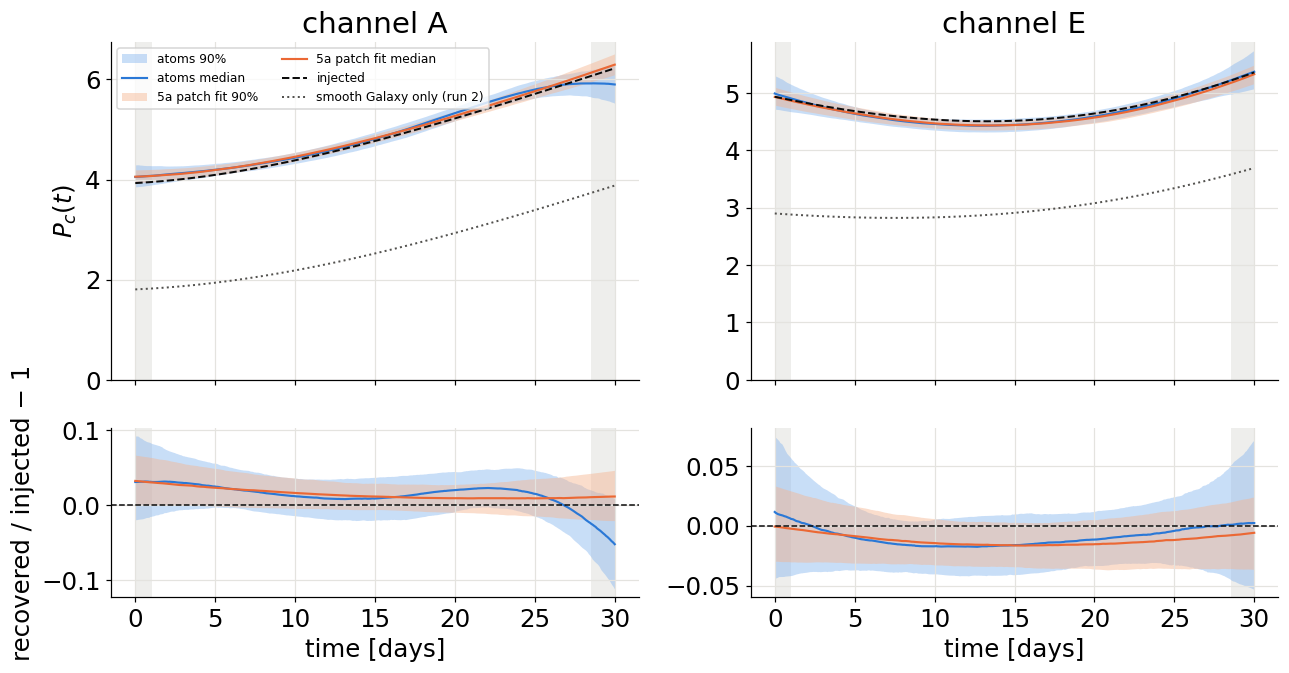

A atoms: median |rec/inj - 1| 0.017, median 90% width 0.056, truth inside 90% band 100% of the analysed time
A 5a   : median |rec/inj - 1| 0.012, median 90% width 0.042, truth inside 90% band 92% of the analysed time
E atoms: median |rec/inj - 1| 0.012, median 90% width 0.049, truth inside 90% band 100% of the analysed time
E 5a   : median |rec/inj - 1| 0.014, median 90% width 0.043, truth inside 90% band 100% of the analysed time


In [8]:
td = t_fine / DAY
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for i, c in enumerate(CH):
    ax, axr = axes[:, i]
    for B, cl, cd, lab in ((B_at, C_AT_L, C_AT, 'atoms'), (B_pf, C_PF_L, C_PF, '5a patch fit')):
        q = np.percentile(B[:, i] * P_true[i], [5, 50, 95], axis=0)
        ax.fill_between(td, q[0], q[2], color=cl, alpha=0.45, lw=0, label=f'{lab} 90%')
        ax.plot(td, q[1], color=cd, lw=1.4, label=f'{lab} median')
        r = np.percentile(B[:, i], [5, 50, 95], axis=0)
        axr.fill_between(td, r[0] - 1, r[2] - 1, color=cl, alpha=0.45, lw=0)
        axr.plot(td, r[1] - 1, color=cd, lw=1.4)
    ax.plot(td, P_true[i], color=C_TRUTH, ls='--', lw=1.3, label='injected')
    ax.plot(td, P_gal_true[i], color=C_MUTED, ls=':', lw=1.3, label='smooth Galaxy only (run 2)')
    axr.axhline(0, color=C_TRUTH, ls='--', lw=1)
    for a in (ax, axr):
        a.axvspan(td[0], an[0] / DAY, color='#eeeeec', lw=0, zorder=0)
        a.axvspan(an[-1] / DAY, td[-1], color='#eeeeec', lw=0, zorder=0)
    ax.set_title(f'channel {c}'); ax.set_ylim(0, None)
    axr.set_xlabel('time [days]')
axes[0, 0].set_ylabel(r'$P_c(t)$'); axes[1, 0].set_ylabel('recovered / injected − 1')
axes[0, 0].legend(fontsize=8, loc='upper left', ncol=2)
fig.tight_layout()
fig.savefig(OUT / 'modulation_5a_vs_atoms.png', dpi=150)
plt.show()

for i, c in enumerate(CH):
    for B, lab in ((B_at, 'atoms'), (B_pf, '5a   ')):
        r = np.percentile(B[:, i][:, win], [5, 50, 95], axis=0)
        cov = np.mean((r[0] <= 1) & (1 <= r[2]))
        print(f"{c} {lab}: median |rec/inj - 1| {np.median(np.abs(r[1] - 1)):.3f}, median 90% width {np.median(r[2] - r[0]):.3f}, "
              f"truth inside 90% band {100 * cov:.0f}% of the analysed time")

### 4b. What 5a attributes to each patch
Each patch's contribution $F_i T_{c,i}(t)$ relative to the true smooth Galaxy, posterior 90% band vs truth (dashed).

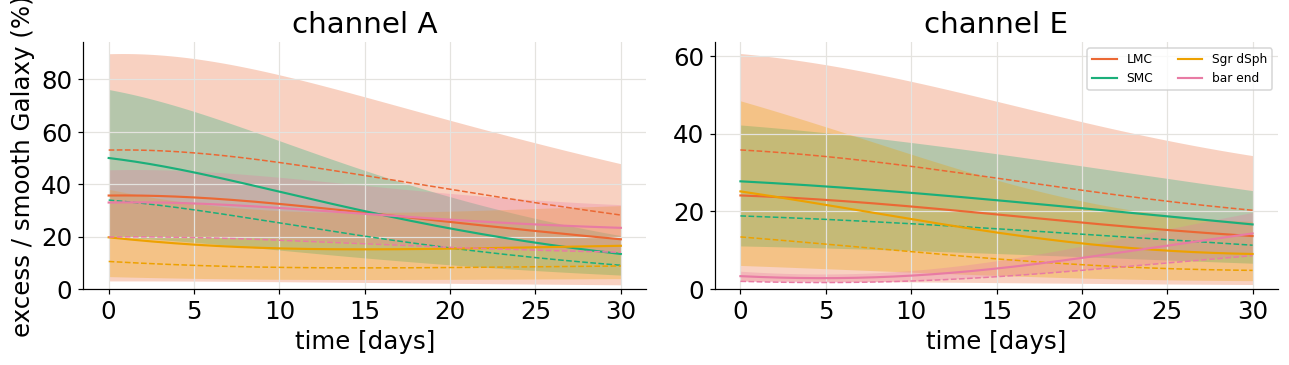

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for c, ax in enumerate(axes):
    for j, (n, col) in enumerate(zip(r_pf['patch_names'], C_PATCH)):
        contrib = r_pf['flux_chain'][i_pf, j][:, None] * T_fine[c, :, 1 + j][None] / P_gal_true[c]
        q = np.percentile(100 * contrib, [5, 50, 95], axis=0)
        ax.fill_between(td, q[0], q[2], color=col, alpha=0.3, lw=0)
        ax.plot(td, q[1], color=col, lw=1.4, label=str(n))
        ax.plot(td, 100 * r_pf['flux_true'][j] * T_fine[c, :, 1 + j] / P_gal_true[c], color=col, ls='--', lw=1)
    ax.set_title(f'channel {CH[c]}'); ax.set_xlabel('time [days]'); ax.set_ylim(0, None)
axes[0].set_ylabel('excess / smooth Galaxy (%)'); axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(OUT / 'patch_contributions_5a.png', dpi=150); plt.show()